# Planeador de desayunos para hoteles
**Costos, inventario y escenarios de ocupación** · Programación ADMI 1301 · Proyecto final (Opción A)

**Integrantes:** Daniela Pardo 202322488, Andres Nohra 202617590, Juliana Gomez 202617280, Silvana Rodriguez 202620895

---
## 1. ¿Para quién es y qué problema resuelve?
**Para quién:** administradores y encargados de cocina de hoteles pequeños y medianos que ofrecen desayuno a sus huéspedes.

**Problema:** cada día hay que decidir cuántos insumos comprar (huevos, arepas, pancakes, café, naranjas…) sin saber con exactitud qué pedirá cada huésped. Si se compra menos de lo necesario, no se logra atender todos los pedidos. Si se compra de más, se desperdician alimentos y se pierde dinero.

**Qué hace esta aplicación:** a partir de los pedidos del día
1. calcula los insumos necesarios,
2. calcula el costo por desayuno y el margen frente al precio de venta,
3. avisa si el inventario no alcanza,
4. compara escenarios de ocupación baja, media y llena (cuánto comprar y cuánta ganancia deja cada uno).

**Cómo ejecutarlo:** menú *Entorno de ejecución → Ejecutar todo*. No necesita archivos externos: los datos de referencia están en la sección 2 y se pueden cambiar por los de cualquier hotel.

> Los precios, el inventario, los pedidos y la cantidad de habitaciones son **valores de referencia** (inspirados en un hotel pequeño de Bogotá, pero no son datos reales de ese hotel).

In [ ]:
# Librerías que usa el proyecto
import math
import pandas as pd
import matplotlib.pyplot as plt

## 2. Datos de entrada (valores de referencia: se pueden modificar)
- `PRECIO_DESAYUNO`: lo que paga el huésped por desayuno.
- `OTROS_COSTOS`: costo por desayuno que no son ingredientes (mano de obra, gas, servicios).
- `HABITACIONES`: habitaciones del hotel.
- `RECETAS`: qué insumos y cuánta cantidad lleva cada opción del menú, por persona.
- `COSTOS`: costo unitario de cada insumo.
- `inventario`: lo que hay en bodega hoy.

In [ ]:
PRECIO_DESAYUNO = 32000     # pesos por desayuno
OTROS_COSTOS = 8000         # pesos por desayuno (mano de obra, gas, servicios) - valor de referencia
HABITACIONES = 20           # habitaciones del hotel

# Qué insumos usa cada opción del menú, por persona
RECETAS = {
    "huevos": {
        "revueltos": {"huevos": 2},
        "fritos":    {"huevos": 2},
        "pochados":  {"huevos": 2},
    },
    "acompanamiento": {
        "arepa":    {"arepas": 1},
        "pancakes": {"mezcla_pancakes_g": 80},
        "pan":      {"pan_unidades": 2},
    },
    "proteina": {
        "tocino":    {"tocino_lonjas": 3},
        "salchicha": {"salchichas": 2},
        "jamon":     {"jamon_lonjas": 2},
    },
    "bebida": {
        "cafe":      {"cafe_g": 12},
        "jugo":      {"naranjas": 3},
        "chocolate": {"chocolate_g": 25},
    },
}

# Costo de cada insumo (pesos por unidad o por gramo)
COSTOS = {
    "huevos": 700, "arepas": 800, "mezcla_pancakes_g": 12,
    "pan_unidades": 500, "tocino_lonjas": 900, "salchichas": 1100,
    "jamon_lonjas": 700, "cafe_g": 60, "naranjas": 400, "chocolate_g": 45,
}

# Inventario disponible hoy
inventario = {
    "huevos": 40, "arepas": 25, "mezcla_pancakes_g": 3000,
    "pan_unidades": 30, "tocino_lonjas": 60, "salchichas": 30,
    "jamon_lonjas": 40, "cafe_g": 400, "naranjas": 60, "chocolate_g": 500,
}

## 3. Pedidos del día
Cada pedido es un diccionario (una habitación). Todas las personas de la habitación piden lo mismo.

In [ ]:
pedidos = [
    {"habitacion": 101, "personas": 2, "huevos": "revueltos", "acompanamiento": "arepa",    "proteina": "tocino",    "bebida": "cafe"},
    {"habitacion": 102, "personas": 1, "huevos": "fritos",    "acompanamiento": "pan",      "proteina": "jamon",     "bebida": "jugo"},
    {"habitacion": 203, "personas": 3, "huevos": "pochados",  "acompanamiento": "pancakes", "proteina": "salchicha", "bebida": "chocolate"},
    {"habitacion": 204, "personas": 2, "huevos": "revueltos", "acompanamiento": "arepa",    "proteina": "salchicha", "bebida": "cafe"},
    {"habitacion": 305, "personas": 2, "huevos": "fritos",    "acompanamiento": "pancakes", "proteina": "tocino",    "bebida": "jugo"},
]
print("Pedidos registrados:", len(pedidos))

Pedidos registrados: 5


## 4. Funciones
- `insumos_de_pedidos`: recorre los pedidos con un ciclo `for` y suma los insumos de cada categoría.
- `costo_de_insumos`: convierte las cantidades de insumos en pesos.
- `revisar_inventario`: compara lo necesario con lo que hay y devuelve lo que falta (condicional).
- `pesos`: da formato de pesos a un número, solo para mostrar.

In [ ]:
def insumos_de_pedidos(lista_pedidos):
    """Suma los insumos necesarios para una lista de pedidos."""
    total = {}
    for pedido in lista_pedidos:
        for categoria in ["huevos", "acompanamiento", "proteina", "bebida"]:
            opcion = pedido[categoria]                      # ej. "arepa"
            receta = RECETAS[categoria][opcion]             # ej. {"arepas": 1}
            for insumo, cantidad in receta.items():
                total[insumo] = total.get(insumo, 0) + cantidad * pedido["personas"]
    return total


def costo_de_insumos(insumos):
    """Costo en pesos de un diccionario de insumos."""
    costo = 0
    for insumo, cantidad in insumos.items():
        costo += cantidad * COSTOS[insumo]
    return costo


def revisar_inventario(insumos, stock):
    """Devuelve un diccionario con lo que falta (vacío si todo alcanza)."""
    faltantes = {}
    for insumo, cantidad in insumos.items():
        if cantidad > stock.get(insumo, 0):
            faltantes[insumo] = cantidad - stock.get(insumo, 0)
    return faltantes


def pesos(valor):
    """Formato de pesos: 1234567 -> $1.234.567"""
    return "$" + f"{valor:,.0f}".replace(",", ".")

## 5. Reporte del día
Con los pedidos de hoy: insumos necesarios, costo por desayuno, ganancia, margen y alerta de inventario.

In [ ]:
num_desayunos = sum(p["personas"] for p in pedidos)
insumos_dia = insumos_de_pedidos(pedidos)
costo_dia = costo_de_insumos(insumos_dia) + num_desayunos * OTROS_COSTOS
ingreso_dia = num_desayunos * PRECIO_DESAYUNO
ganancia_dia = ingreso_dia - costo_dia

print("=== REPORTE DEL DÍA ===")
print("Desayunos a servir:", num_desayunos)
print("\nInsumos necesarios:")
for insumo, cantidad in insumos_dia.items():
    print(f"  {insumo}: {cantidad}")

print(f"\nCosto por desayuno: {pesos(costo_dia / num_desayunos)}")
print(f"Ingreso: {pesos(ingreso_dia)} | Costo: {pesos(costo_dia)} | Ganancia: {pesos(ganancia_dia)}")
print(f"Margen: {ganancia_dia / ingreso_dia * 100:.1f} %")

faltan = revisar_inventario(insumos_dia, inventario)
if faltan:
    print("\n⚠ ALERTA: el inventario NO alcanza:")
    for insumo, falta in faltan.items():
        print(f"  Faltan {falta} de {insumo}")
else:
    print("\n✔ El inventario alcanza para todos los pedidos.")

=== REPORTE DEL DÍA ===
Desayunos a servir: 10

Insumos necesarios:
  huevos: 20
  arepas: 4
  tocino_lonjas: 12
  cafe_g: 48
  pan_unidades: 2
  jamon_lonjas: 2
  naranjas: 9
  mezcla_pancakes_g: 400
  salchichas: 10
  chocolate_g: 75

Costo por desayuno: $13.606
Ingreso: $320.000 | Costo: $136.055 | Ganancia: $183.945
Margen: 57.5 %

✔ El inventario alcanza para todos los pedidos.


## 6. Escenarios de ocupación
Supuesto: en cualquier escenario, los huéspedes piden en la misma proporción que hoy. Así, los insumos del escenario son los de hoy multiplicados por un factor (desayunos del escenario ÷ desayunos de hoy). Los insumos se redondean **hacia arriba** porque no se pueden comprar fracciones.

In [ ]:
personas_por_habitacion = num_desayunos / len(pedidos)    # promedio del día

def escenario(ocupacion):
    """Calcula todo para una ocupación (0 a 1)."""
    desayunos = round(HABITACIONES * ocupacion * personas_por_habitacion)
    factor = desayunos / num_desayunos
    insumos = {}
    for insumo, cantidad in insumos_dia.items():
        insumos[insumo] = math.ceil(cantidad * factor)
    costo = costo_de_insumos(insumos) + desayunos * OTROS_COSTOS
    ingreso = desayunos * PRECIO_DESAYUNO
    return {
        "desayunos": desayunos,
        "insumos": insumos,
        "costo": costo,
        "ingreso": ingreso,
        "ganancia": ingreso - costo,
        "faltantes": revisar_inventario(insumos, inventario),
    }

escenarios = {"Baja (30 %)": 0.3, "Media (60 %)": 0.6, "Llena (100 %)": 1.0}
resultados = {nombre: escenario(ocupacion) for nombre, ocupacion in escenarios.items()}

### Tabla 1. Resumen de los escenarios

In [ ]:
filas = []
for nombre, r in resultados.items():
    filas.append({
        "Escenario": nombre,
        "Desayunos": r["desayunos"],
        "Ingreso": pesos(r["ingreso"]),
        "Costo": pesos(r["costo"]),
        "Ganancia": pesos(r["ganancia"]),
        "Margen (%)": round(r["ganancia"] / r["ingreso"] * 100, 1),
        "Insumos que faltan": len(r["faltantes"]),
    })
tabla_escenarios = pd.DataFrame(filas)
tabla_escenarios

,Escenario,Desayunos,Ingreso,Costo,Ganancia,Margen (%),Insumos que faltan
0,Baja (30 %),12,$384.000,$164.790,$219.210,57.1,0
1,Media (60 %),24,$768.000,$327.480,$440.520,57.4,1
2,Llena (100 %),40,$1.280.000,$544.220,$735.780,57.5,2


### Tabla 2. Cuánto comprar en cada escenario
Cada columna es lo que se necesita en ese escenario. La última columna es el inventario actual, y las filas marcadas con ⚠ son los insumos que no alcanzan en alguno de los escenarios.

In [ ]:
tabla_insumos = pd.DataFrame({nombre: r["insumos"] for nombre, r in resultados.items()})
tabla_insumos["Inventario hoy"] = pd.Series(inventario)
alerta = []
for insumo in tabla_insumos.index:
    falta = any(insumo in r["faltantes"] for r in resultados.values())
    alerta.append("⚠ falta" if falta else "ok")
tabla_insumos["Estado"] = alerta
tabla_insumos

,Baja (30 %),Media (60 %),Llena (100 %),Inventario hoy,Estado
huevos,24,48,80,40,⚠ falta
arepas,5,10,16,25,ok
tocino_lonjas,15,29,48,60,ok
cafe_g,58,116,192,400,ok
pan_unidades,3,5,8,30,ok
jamon_lonjas,3,5,8,40,ok
naranjas,11,22,36,60,ok
mezcla_pancakes_g,480,960,1600,3000,ok
salchichas,12,24,40,30,⚠ falta
chocolate_g,90,180,300,500,ok


### Figura 1. Ganancia según la ocupación
Se calcula la ganancia para ocupaciones de 10 % a 100 % y se marcan los tres escenarios.

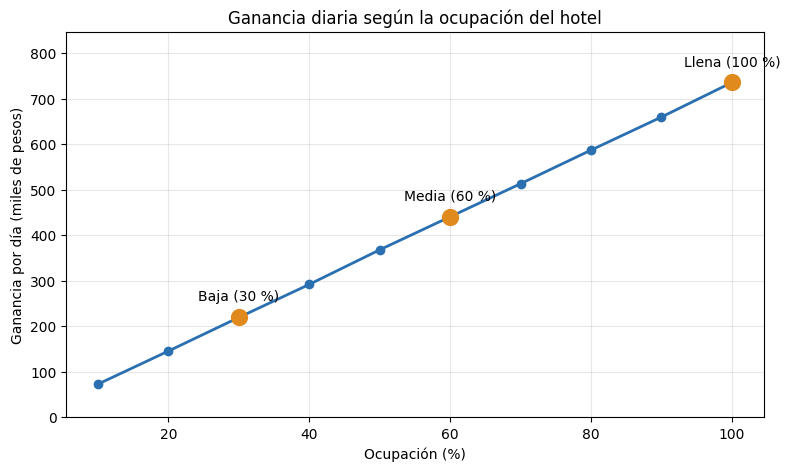

In [ ]:
porcentajes = list(range(10, 101, 10))
ganancias = []
for p in porcentajes:
    ganancias.append(escenario(p / 100)["ganancia"] / 1000)   # en miles de pesos

plt.figure(figsize=(9, 5))
plt.plot(porcentajes, ganancias, marker="o", color="#2a6fb0", linewidth=2, label="Ganancia")

# Marcar los tres escenarios
for nombre, ocupacion in escenarios.items():
    g = resultados[nombre]["ganancia"] / 1000
    plt.scatter(ocupacion * 100, g, s=130, color="#e08a1e", zorder=3)
    plt.annotate(nombre, (ocupacion * 100, g), xytext=(0, 12), textcoords="offset points", ha="center")

plt.title("Ganancia diaria según la ocupación del hotel")
plt.xlabel("Ocupación (%)")
plt.ylabel("Ganancia por día (miles de pesos)")
plt.ylim(0, max(ganancias) * 1.15)       # deja espacio arriba para las etiquetas
plt.grid(alpha=0.3)
plt.show()

In [ ]:
def mostrar_reporte():
    """Opción 1: reporte del día con los pedidos de hoy."""
    print("\n=== REPORTE DEL DÍA ===")
    print("Desayunos a servir:", num_desayunos)
    print(f"Costo por desayuno: {pesos(costo_dia / num_desayunos)}")
    print(f"Ingreso: {pesos(ingreso_dia)} | Costo: {pesos(costo_dia)} | Ganancia: {pesos(ganancia_dia)}")
    print(f"Margen: {ganancia_dia / ingreso_dia * 100:.1f} %")
    faltan = revisar_inventario(insumos_dia, inventario)
    if faltan:
        print("ALERTA: el inventario NO alcanza:")
        for insumo, falta in faltan.items():
            print(f"  Faltan {falta} de {insumo}")
    else:
        print("El inventario alcanza para todos los pedidos.")


def consultar_insumo():
    """Opción 2: el jefe de cocina escribe un insumo y ve cuánto falta."""
    print("\nInsumos disponibles:", ", ".join(inventario.keys()))
    nombre = input("¿Qué insumo quiere consultar? ").strip().lower().replace(" ", "_")
    if nombre not in inventario:
        print("Ese insumo no existe. Revise el nombre e intente de nuevo.")
        return
    necesario = insumos_dia.get(nombre, 0)      # lo que piden los pedidos de hoy
    hay = inventario[nombre]                    # lo que hay en la cocina
    print(f"\nInsumo: {nombre}")
    print(f"  Necesario hoy: {necesario}")
    print(f"  En inventario: {hay}")
    if necesario > hay:
        print(f"  FALTAN {necesario - hay}")
    else:
        print(f"  Alcanza. Sobran {hay - necesario}")


def ver_alertas():
    """Opción 3: lista los insumos en alerta (no alcanzan para los pedidos de hoy)."""
    faltan = revisar_inventario(insumos_dia, inventario)
    print("\n=== INSUMOS EN ALERTA ===")
    if not faltan:
        print("Ninguno. Todos los insumos alcanzan para los pedidos de hoy.")
    else:
        for insumo, falta in faltan.items():
            print(f"  {insumo}: necesario {insumos_dia[insumo]}, hay {inventario[insumo]}, FALTAN {falta}")


def menu():
    while True:
        print("\n===== MENÚ DEL JEFE DE COCINA =====")
        print("1. Ver el reporte del día")
        print("2. Consultar un insumo")
        print("3. Ver insumos en alerta")
        print("0. Salir")
        opcion = input("Elija una opción: ").strip()
        if opcion == "1":
            mostrar_reporte()
        elif opcion == "2":
            consultar_insumo()
        elif opcion == "3":
            ver_alertas()
        elif opcion == "0":
            print("Hasta luego.")
            break
        else:
            print("Opción no válida. Escriba 1, 2, 3 o 0.")

menu()


===== MENÚ DEL JEFE DE COCINA =====
1. Ver el reporte del día
2. Consultar un insumo
3. Ver insumos en alerta
0. Salir

Insumos disponibles: huevos, arepas, mezcla_pancakes_g, pan_unidades, tocino_lonjas, salchichas, jamon_lonjas, cafe_g, naranjas, chocolate_g

Insumo: huevos
  Necesario hoy: 20
  En inventario: 40
  Alcanza. Sobran 20

===== MENÚ DEL JEFE DE COCINA =====
1. Ver el reporte del día
2. Consultar un insumo
3. Ver insumos en alerta
0. Salir

=== REPORTE DEL DÍA ===
Desayunos a servir: 10
Costo por desayuno: $13.606
Ingreso: $320.000 | Costo: $136.055 | Ganancia: $183.945
Margen: 57.5 %
El inventario alcanza para todos los pedidos.

===== MENÚ DEL JEFE DE COCINA =====
1. Ver el reporte del día
2. Consultar un insumo
3. Ver insumos en alerta
0. Salir

Insumos disponibles: huevos, arepas, mezcla_pancakes_g, pan_unidades, tocino_lonjas, salchichas, jamon_lonjas, cafe_g, naranjas, chocolate_g

Insumo: huevos
  Necesario hoy: 20
  En inventario: 40
  Alcanza. Sobran 20

===== M

## 7. Resultados y limitaciones

*Qué muestran los resultados:*
- Al pasar de ocupación baja (30 %, 12 desayunos) a ocupación llena (100 %, 40 desayunos), la ganancia diaria sube de 219.210 a 735.780 (un aumento de $516.570), manteniendo un margen cercano al 57 % en los tres escenarios.
- En ocupación baja (30 %) no hay faltantes, pero el inventario empieza a quedarse corto en ocupación media (60 %, falta 1 insumo) y aún más en ocupación llena (100 %, faltan 2 insumos).
- Los primeros insumos a reponer son los huevos (se necesitan 48 en ocupación media y 80 en ocupación llena frente a 40 disponibles hoy, faltando 8 y 40 unidades respectivamente) y las salchichas (se necesitan 40 en ocupación llena frente a 30 disponibles hoy, faltando 10 unidades).

*Limitaciones:*
- Los precios, el inventario y los pedidos son valores de referencia, no datos reales de un hotel.
- Se supone que en todos los escenarios los huéspedes piden en la misma proporción que en el día de ejemplo.
- No se consideran desperdicios, vencimientos ni variaciones de precio de los insumos.
- Todos los huéspedes de una habitación piden lo mismo.

*Cómo adaptarlo a otro hotel:* cambiar `PRECIO_DESAYUNO`, `OTROS_COSTOS`, `HABITACIONES`, `RECETAS`, `COSTOS`, `inventario` y la lista `pedidos` en las secciones 2 y 3, y volver a ejecutar todo.

8.** Uso de inteligencia artificial**


Herramientas utilizadas: Claude


Para qué tareas: Guía para la estructura del código, optimización del código y detección de errores o inconsistencias.


Como verificamos los resultados: Para empezar rectificamos cada sugerencia hecha por IA en el codigo y comprobamos que estas aportaran al correcto funcionamiento de este. Ejecutamos el programa con pedidos de prueba, comprobamos los calculos a mano, y por ultimo nos aseguramos que las graficas coincidieran con las tablas.


Qué entendemos y podemos explicar: Entendemos la totalidad del codigo presentado en el notebook, los componentes que lo conforman, y las funciones que este ayuda a realizar.